In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error,r2_score

In [72]:
housing = fetch_california_housing()
data=pd.DataFrame(housing.data,columns=housing.feature_names)
data["Price"]=housing.target



In [73]:
x =  data[["AveRooms"]].values
y = data["Price"].values

In [74]:
data.shape

(20640, 9)

In [75]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [76]:
scaler=StandardScaler()

In [77]:
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)
x_train_scaled

array([[-0.17491646],
       [-0.40283542],
       [ 0.08821601],
       ...,
       [-0.60675918],
       [ 0.40217517],
       [-0.85144571]], shape=(16512, 1))

In [78]:
w=0
b=0
cost_history=[]
learning_rate=0.01
epochs=1000

In [80]:
n=len(x_train_scaled)
for i in range(epochs):
    y_pred= w * x_train_scaled.flatten() + b
    dw=(1/n)*np.sum((y_pred-y_train)*x_train_scaled.flatten())
    db=(1/n)*np.sum((y_pred-y_train))
    w=w-learning_rate*dw
    b=b-learning_rate*db
    cost=(1/(2*n))*np.sum((y_pred-y_train)**2)
    cost_history.append(cost)
    
    if i%100==0:
       print(f"epoch{i},cost={cost:.4f}")
y_pred_gd=w*x_test_scaled.flatten()+b    

epoch0,cost=0.6516
epoch100,cost=0.6516
epoch200,cost=0.6516
epoch300,cost=0.6516
epoch400,cost=0.6516
epoch500,cost=0.6516
epoch600,cost=0.6516
epoch700,cost=0.6516
epoch800,cost=0.6516
epoch900,cost=0.6516


In [81]:
print(x_train_scaled.shape)

(16512, 1)


In [82]:
print("Gradient Descent")
print("-----------------")
print("Weight:",w)
print("bias:",b)
print("MSE:",mean_squared_error(y_test,y_pred_gd))
print("r2_score:",r2_score(y_test,y_pred_gd))



Gradient Descent
-----------------
Weight: 0.18323881679340234
bias: 2.0719469335172715
MSE: 1.2923314439168279
r2_score: 0.013795337657361961


In [83]:
#normal equation

x_train_ne=np.c_[np.ones((len(x_train),1)),x_train]
x_test_ne=np.c_[np.ones((len(x_test),1)),x_test]
theta=np.linalg.inv(x_train_ne.T@ x_train_ne)@ x_train_ne.T@ y_train
y_pred_ne=x_test_ne @ theta

print("Matrix method")
print("-----------------")
print("Intercept:",theta[0])
print("slope:",theta[1])
print("MSE:",mean_squared_error(y_test,y_pred_gd))
print("r2_score:",r2_score(y_test,y_pred_gd))

Matrix method
-----------------
Intercept: 1.6547622685968417
slope: 0.07675558963126736
MSE: 1.2923314439168279
r2_score: 0.013795337657361961


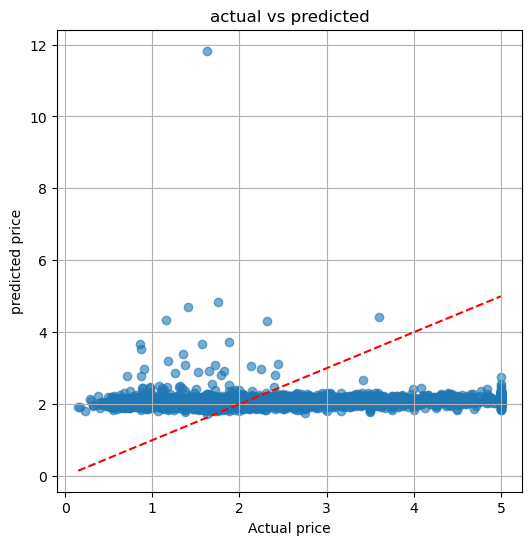

In [86]:
plt.figure(figsize=(6,6))
plt.scatter(y_test,y_pred_gd,alpha=0.6)
plt.plot([y_test.min(),y_test.max()],
         [y_test.min(),y_test.max()],
         'r--')
plt.xlabel("Actual price")
plt.ylabel("predicted price")
plt.title("actual vs predicted")
plt.grid(True)

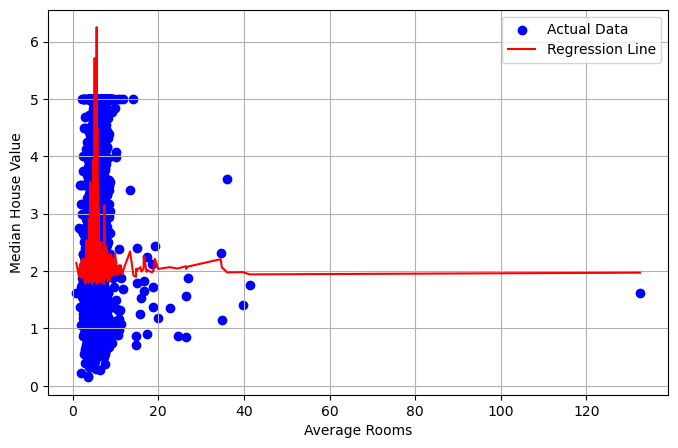

In [14]:
index = np.argsort(x_test.flatten())

plt.figure(figsize=(8,5))

plt.scatter(x_test, y_test, color='blue', label='Actual Data')

plt.plot(x_test.flatten()[index],
         y_pred[index],
         color='red',
         label='Regression Line')

plt.xlabel("Average Rooms")
plt.ylabel("Median House Value")
plt.legend()
plt.grid(True)
plt.show()


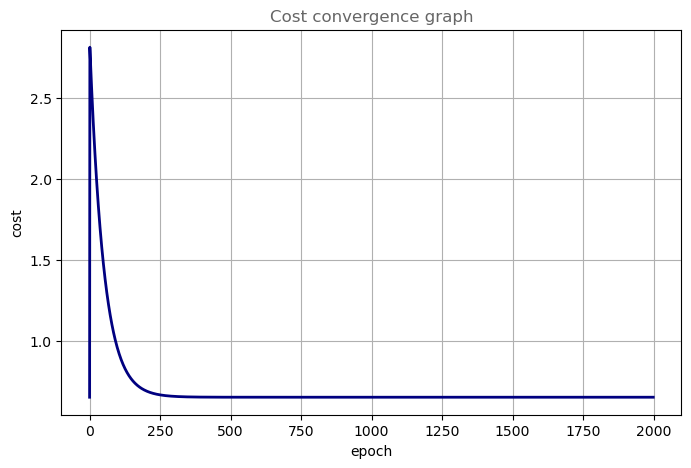

In [85]:
plt.figure(figsize=(8,5))
plt.plot(cost_history,color="navy",linewidth=2)
plt.xlabel("epoch")
plt.ylabel("cost")
plt.title("gradient descent cost convergence curve")
plt.title("Cost convergence graph",alpha=0.6)
plt.grid(True)